# 04 · Section-Aware BERT (final model)

**The model reported in the paper.** In this notebook it is called **Title-Aware BERT**: the title becomes its own section (64 tokens) next to Responsibilities, Requirements and Other (256 tokens each), encoded by a shared BERT and fused by multi-head attention.

Contains the training run, prediction and attention-weight export, a linguistic error analysis, and the comparison with baseline BERT. Final numbers: see the paper.

NEW SECTION AWARE BERT

In [ ]:
# Inspect 5 random samples
sample = test_df.sample(5)
for i, row in sample.iterrows():
    print("=" * 60)
    print(f"TITLE: {row['title']}")
    print(f"\nRESP: {str(row['section_responsibilities'])[:300]}...")
    print(f"\nREQ: {str(row['section_requirements'])[:300]}...")

TITLE: Commercial Bond Policy Issuer

RESP: Enter variety of data using current technologyCreate and maintain logs for tracking purposesReview discrepancies in data received and advise supervisor of issuesIssue new bonds that come through Surety Cloud - Verify that the info given by agents is accurate and meets the requirements for the bond f...

REQ: Previous experience in policy issuing, data entry or other related fieldsExcellent communication and typing skillsStrong organizational skillsDeadline and detail-orientedShow eagerness and capacity to learn Risk Strategies is the 9th largest privately held US brokerage firm offering comprehensive ri...
TITLE: Tax Director

RESP: VISION: Seeking a Tax Director who has UPSIDE to senior leadership roles. These are expansionary hires for this elite tax team. Work with national firm groomed CPA/MST professionals with hands-on world class knowledge that can train and mentor also. Be exposed to cutting edge technology, business le...

REQ: Must 

In [ ]:
# ============================================================================
# TITLE-AWARE BERT (improved Section-Aware BERT)
# ============================================================================
#
# Change: the title is encoded as its own section
#
# Architecture:
#   ├── Title (64 tokens)           ← new: encoded separately
#   ├── Responsibilities (256 tokens)
#   ├── Requirements (256 tokens)
#   └── Other (256 tokens)
#            │
#            ▼
#      Multi-Head Attention (learns the importance of each section)
#            │
#            ▼
#        Classifier
#
# ============================================================================

import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import BertModel, BertTokenizer, get_linear_schedule_with_warmup
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# === Mount Google Drive ===
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Model will be saved to: {SAVE_DIR}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ============================================================================
# Config
# ============================================================================
class Config:
    # Data
    train_path = 'train_data_final.csv'
    dev_path = 'dev_data_final.csv'
    test_path = 'test_data_final.csv'

    # Model
    bert_model = 'bert-base-uncased'
    title_max_length = 64      # The title is encoded separately and is shorter
    section_max_length = 256   # Other sections
    num_classes = 4
    hidden_size = 768
    num_attention_heads = 8
    dropout = 0.1

    # Training
    batch_size = 16
    epochs = 3
    learning_rate = 2e-5
    warmup_ratio = 0.1

    # Label mapping
    label2id = {'Entry': 0, 'Mid': 1, 'Senior': 2, 'Executive': 3}
    id2label = {0: 'Entry', 1: 'Mid', 2: 'Senior', 3: 'Executive'}

config = Config()

# ============================================================================
# Dataset - Title-Aware (4 sections)
# ============================================================================
class TitleAwareDataset(Dataset):
    def __init__(self, df, tokenizer, config):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.config = config

    def __len__(self):
        return len(self.df)

    def _safe_str(self, val):
        """Safely convert to a string, handling NaN and 'N/A'"""
        if pd.isna(val) or val == 'N/A' or val == '':
            return ''
        return str(val)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Get the 4 sections
        title = self._safe_str(row['title'])
        resp = self._safe_str(row['section_responsibilities'])
        req = self._safe_str(row['section_requirements'])
        other = self._safe_str(row['section_other'])

        # Tokenize the title (shorter)
        title_encoding = self.tokenizer(
            title,
            max_length=self.config.title_max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        # Tokenize Responsibilities
        resp_encoding = self.tokenizer(
            resp,
            max_length=self.config.section_max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        # Tokenize Requirements
        req_encoding = self.tokenizer(
            req,
            max_length=self.config.section_max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        # Tokenize Other
        other_encoding = self.tokenizer(
            other,
            max_length=self.config.section_max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        label = self.config.label2id[row['experience_level']]

        return {
            'title_input_ids': title_encoding['input_ids'].squeeze(0),
            'title_attention_mask': title_encoding['attention_mask'].squeeze(0),
            'resp_input_ids': resp_encoding['input_ids'].squeeze(0),
            'resp_attention_mask': resp_encoding['attention_mask'].squeeze(0),
            'req_input_ids': req_encoding['input_ids'].squeeze(0),
            'req_attention_mask': req_encoding['attention_mask'].squeeze(0),
            'other_input_ids': other_encoding['input_ids'].squeeze(0),
            'other_attention_mask': other_encoding['attention_mask'].squeeze(0),
            'label': torch.tensor(label, dtype=torch.long)
        }

# ============================================================================
# Title-Aware BERT Model (4 sections)
# ============================================================================
class TitleAwareBERT(nn.Module):
    def __init__(self, config):
        super(TitleAwareBERT, self).__init__()

        self.config = config

        # Shared BERT encoder
        self.bert = BertModel.from_pretrained(config.bert_model)

        # Multi-Head Self-Attention for fusion (4 sections)
        self.fusion_attention = nn.MultiheadAttention(
            embed_dim=config.hidden_size,
            num_heads=config.num_attention_heads,
            dropout=config.dropout,
            batch_first=True
        )

        # Layer Norm
        self.layer_norm = nn.LayerNorm(config.hidden_size)

        # Classification head
        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.hidden_size, config.num_classes)

    def forward(self, title_input_ids, title_attention_mask,
                resp_input_ids, resp_attention_mask,
                req_input_ids, req_attention_mask,
                other_input_ids, other_attention_mask):

        # === 1. Encode the 4 sections separately ===

        # Title (new)
        title_outputs = self.bert(
            input_ids=title_input_ids,
            attention_mask=title_attention_mask
        )
        title_cls = title_outputs.pooler_output  # [batch, 768]

        # Responsibilities
        resp_outputs = self.bert(
            input_ids=resp_input_ids,
            attention_mask=resp_attention_mask
        )
        resp_cls = resp_outputs.pooler_output  # [batch, 768]

        # Requirements
        req_outputs = self.bert(
            input_ids=req_input_ids,
            attention_mask=req_attention_mask
        )
        req_cls = req_outputs.pooler_output  # [batch, 768]

        # Other
        other_outputs = self.bert(
            input_ids=other_input_ids,
            attention_mask=other_attention_mask
        )
        other_cls = other_outputs.pooler_output  # [batch, 768]

        # === 2. Stack into a sequence [batch, 4, 768] ===
        # The title comes first
        section_embeddings = torch.stack([title_cls, resp_cls, req_cls, other_cls], dim=1)

        # === 3. Fuse with multi-head self-attention ===
        attn_output, attn_weights = self.fusion_attention(
            section_embeddings,
            section_embeddings,
            section_embeddings
        )

        # Residual connection + Layer Norm
        fused = self.layer_norm(section_embeddings + attn_output)

        # === 4. Pooling: weighted or simple average ===
        pooled = fused.mean(dim=1)  # [batch, 768]

        # === 5. Classification ===
        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)  # [batch, 4]

        return logits, attn_weights

# ============================================================================
# Training Function
# ============================================================================
def train_epoch(model, dataloader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    predictions = []
    true_labels = []

    progress_bar = tqdm(dataloader, desc='Training')

    for batch in progress_bar:
        optimizer.zero_grad()

        # Get the inputs of the 4 sections
        title_input_ids = batch['title_input_ids'].to(device)
        title_attention_mask = batch['title_attention_mask'].to(device)
        resp_input_ids = batch['resp_input_ids'].to(device)
        resp_attention_mask = batch['resp_attention_mask'].to(device)
        req_input_ids = batch['req_input_ids'].to(device)
        req_attention_mask = batch['req_attention_mask'].to(device)
        other_input_ids = batch['other_input_ids'].to(device)
        other_attention_mask = batch['other_attention_mask'].to(device)
        labels = batch['label'].to(device)

        logits, _ = model(
            title_input_ids, title_attention_mask,
            resp_input_ids, resp_attention_mask,
            req_input_ids, req_attention_mask,
            other_input_ids, other_attention_mask
        )

        loss = F.cross_entropy(logits, labels)
        total_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        preds = torch.argmax(logits, dim=1).cpu().numpy()
        predictions.extend(preds)
        true_labels.extend(labels.cpu().numpy())

        progress_bar.set_postfix({'loss': f'{loss.item():.4f}'})

    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='weighted')

    return avg_loss, accuracy, f1

# ============================================================================
# Evaluation Function
# ============================================================================
def evaluate(model, dataloader, device):
    model.eval()
    total_loss = 0
    predictions = []
    true_labels = []
    all_attn_weights = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating'):
            title_input_ids = batch['title_input_ids'].to(device)
            title_attention_mask = batch['title_attention_mask'].to(device)
            resp_input_ids = batch['resp_input_ids'].to(device)
            resp_attention_mask = batch['resp_attention_mask'].to(device)
            req_input_ids = batch['req_input_ids'].to(device)
            req_attention_mask = batch['req_attention_mask'].to(device)
            other_input_ids = batch['other_input_ids'].to(device)
            other_attention_mask = batch['other_attention_mask'].to(device)
            labels = batch['label'].to(device)

            logits, attn_weights = model(
                title_input_ids, title_attention_mask,
                resp_input_ids, resp_attention_mask,
                req_input_ids, req_attention_mask,
                other_input_ids, other_attention_mask
            )

            loss = F.cross_entropy(logits, labels)
            total_loss += loss.item()

            preds = torch.argmax(logits, dim=1).cpu().numpy()
            predictions.extend(preds)
            true_labels.extend(labels.cpu().numpy())

            # Keep attention weights for analysis
            all_attn_weights.append(attn_weights.cpu())

    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='weighted')

    return avg_loss, accuracy, f1, predictions, true_labels, all_attn_weights

# ============================================================================
# Main Training
# ============================================================================
def main():
    print("=" * 80)
    print("TITLE-AWARE BERT (4 Sections)")
    print("=" * 80)
    print("\nArchitecture:")
    print("  ├── Title (64 tokens)        ← NEW!")
    print("  ├── Responsibilities (256 tokens)")
    print("  ├── Requirements (256 tokens)")
    print("  └── Other (256 tokens)")
    print("           │")
    print("           ▼")
    print("     Multi-Head Attention")
    print("           │")
    print("           ▼")
    print("       Classifier")
    print("=" * 80)

    # Load data
    print("\n[1] Loading data...")
    train_df = pd.read_csv(config.train_path, keep_default_na=False, na_values=[])
    dev_df = pd.read_csv(config.dev_path, keep_default_na=False, na_values=[])
    test_df = pd.read_csv(config.test_path, keep_default_na=False, na_values=[])

    print(f"Train: {len(train_df)}")
    print(f"Dev: {len(dev_df)}")
    print(f"Test: {len(test_df)}")

    # Check the title column
    print(f"\nTitle column check:")
    print(f"  Non-empty titles: {(train_df['title'].notna() & (train_df['title'] != '')).sum()}/{len(train_df)}")

    # Initialize the tokenizer
    print("\n[2] Initializing tokenizer...")
    tokenizer = BertTokenizer.from_pretrained(config.bert_model)

    # Create Dataset and DataLoader
    print("\n[3] Creating DataLoader...")
    train_dataset = TitleAwareDataset(train_df, tokenizer, config)
    dev_dataset = TitleAwareDataset(dev_df, tokenizer, config)
    test_dataset = TitleAwareDataset(test_df, tokenizer, config)

    train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True)
    dev_loader = DataLoader(dev_dataset, batch_size=config.batch_size)
    test_loader = DataLoader(test_dataset, batch_size=config.batch_size)

    # Initialize the model
    print("\n[4] Initializing Title-Aware BERT...")
    model = TitleAwareBERT(config).to(device)

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Total parameters: {total_params:,}")
    print(f"  Trainable parameters: {trainable_params:,}")

    optimizer = AdamW(model.parameters(), lr=config.learning_rate)
    total_steps = len(train_loader) * config.epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(total_steps * config.warmup_ratio),
        num_training_steps=total_steps
    )

    # Training
    print("\n" + "=" * 80)
    print("Training Title-Aware BERT")
    print("=" * 80)

    best_f1 = 0
    results = []

    for epoch in range(config.epochs):
        print(f"\n--- Epoch {epoch + 1}/{config.epochs} ---")

        train_loss, train_acc, train_f1 = train_epoch(
            model, train_loader, optimizer, scheduler, device
        )

        dev_loss, dev_acc, dev_f1, _, _, _ = evaluate(model, dev_loader, device)

        print(f"Train - Loss: {train_loss:.4f}, Acc: {train_acc:.4f}, F1: {train_f1:.4f}")
        print(f"Dev   - Loss: {dev_loss:.4f}, Acc: {dev_acc:.4f}, F1: {dev_f1:.4f}")

        results.append({
            'epoch': epoch + 1,
            'train_loss': train_loss,
            'train_acc': train_acc,
            'train_f1': train_f1,
            'dev_loss': dev_loss,
            'dev_acc': dev_acc,
            'dev_f1': dev_f1
        })

        if dev_f1 > best_f1:
            best_f1 = dev_f1
            torch.save(model.state_dict(), f'{SAVE_DIR}/title_aware_bert_best.pt')
            print(f"  ✓ Saved best model (F1: {dev_f1:.4f})")

    # Test set evaluation
    print("\n" + "=" * 80)
    print("Test set evaluation")
    print("=" * 80)

    model.load_state_dict(torch.load(f'{SAVE_DIR}/title_aware_bert_best.pt'))
    test_loss, test_acc, test_f1, test_preds, test_labels, attn_weights = evaluate(
        model, test_loader, device
    )

    print(f"\nTitle-Aware BERT Test Results:")
    print(f"  Accuracy: {test_acc:.4f}")
    print(f"  F1 Score: {test_f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        test_labels, test_preds,
        target_names=['Entry', 'Mid', 'Senior', 'Executive']
    ))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(test_labels, test_preds)
    print(pd.DataFrame(
        cm,
        index=['True: Entry', 'True: Mid', 'True: Senior', 'True: Executive'],
        columns=['Pred: Entry', 'Pred: Mid', 'Pred: Senior', 'Pred: Executive']
    ))

    # ============================================================================
    # Attention Weight Analysis
    # ============================================================================
    print("\n" + "=" * 80)
    print("Attention Weight Analysis")
    print("=" * 80)

    # Concatenate all attention weights
    all_weights = torch.cat(attn_weights, dim=0)  # [N, 4, 4]

    # Average attention received by each section (how much the other sections attend to it)
    avg_attn = all_weights.mean(dim=0).mean(dim=0)  # [4]
    section_names = ['Title', 'Responsibilities', 'Requirements', 'Other']

    print("\nAverage attention received by each section:")
    for name, weight in zip(section_names, avg_attn):
        bar = '█' * int(weight * 40)
        print(f"  {name:<18} {weight:.4f} {bar}")

    # ============================================================================
    # Save predictions
    # ============================================================================
    print("\n" + "=" * 80)
    print("Saving predictions")
    print("=" * 80)

    test_df = test_df.reset_index(drop=True)
    test_df['pred_title_aware_bert'] = [config.id2label[p] for p in test_preds]

    if 'text' not in test_df.columns:
        test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

    # Save
    test_df.to_csv(f'{SAVE_DIR}/title_aware_bert_predictions.csv', index=False)
    np.save(f'{SAVE_DIR}/title_aware_bert_test_preds.npy', test_preds)
    np.save(f'{SAVE_DIR}/title_aware_bert_attn_weights.npy', all_weights.numpy())

    print(f"✓ title_aware_bert_predictions.csv saved")
    print(f"✓ title_aware_bert_attn_weights.npy saved")

    # Error analysis
    errors_df = test_df[test_df['experience_level'] != test_df['pred_title_aware_bert']].copy()
    errors_df.to_csv(f'{SAVE_DIR}/title_aware_bert_errors.csv', index=False)
    print(f"✓ title_aware_bert_errors.csv saved ({len(errors_df)} errors)")

    # ============================================================================
    # Compare with other models
    # ============================================================================
    print("\n" + "=" * 80)
    print("Model comparison")
    print("=" * 80)

    comparison_data = [
        ('Title-Aware BERT (4 sections)', test_acc * 100, test_f1)
    ]

    # Try to load the other models' results
    try:
        baseline_df = pd.read_csv(f'{SAVE_DIR}/baseline_bert_predictions.csv')
        baseline_acc = (baseline_df['experience_level'] == baseline_df['pred_baseline_bert']).mean() * 100
        comparison_data.append(('Baseline BERT', baseline_acc, None))
    except:
        pass

    try:
        section_df = pd.read_csv(f'{SAVE_DIR}/bert_predictions.csv')
        section_acc = (section_df['experience_level'] == section_df['pred_bert']).mean() * 100
        comparison_data.append(('Section-Aware BERT (3 sections)', section_acc, None))
    except:
        pass

    print(f"\n{'Model':<35} {'Accuracy':>12}")
    print("-" * 50)
    for name, acc, _ in comparison_data:
        print(f"{name:<35} {acc:>11.2f}%")

    print("\n" + "=" * 80)
    print("Training complete!")
    print("=" * 80)
    print(f"\n📁 All files saved to: {SAVE_DIR}")
    print("   - title_aware_bert_best.pt")
    print("   - title_aware_bert_predictions.csv")
    print("   - title_aware_bert_attn_weights.npy")
    print("   - title_aware_bert_errors.csv")

if __name__ == '__main__':
    main()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
模型将保存到: /content/drive/MyDrive/nlp_project/
Using device: cuda
GPU: NVIDIA A100-SXM4-80GB
TITLE-AWARE BERT (4 Sections)

Architecture:
  ├── Title (64 tokens)        ← NEW!
  ├── Responsibilities (256 tokens)
  ├── Requirements (256 tokens)
  └── Other (256 tokens)
           │
           ▼
     Multi-Head Attention
           │
           ▼
       Classifier

[1] 加载数据...
Train: 56501
Dev: 12108
Test: 12108

Title column check:
  Non-empty titles: 56501/56501

[2] 初始化 Tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]


[3] 创建 DataLoader...

[4] 初始化 Title-Aware BERT...


... (6 outputs left out)

Evaluating: 100%|██████████| 757/757 [04:14<00:00,  2.98it/s]


Train - Loss: 0.3812, Acc: 0.8633, F1: 0.8605
Dev   - Loss: 0.5261, Acc: 0.8209, F1: 0.8181
  ✓ 保存最佳模型 (F1: 0.8181)

测试集评估


Evaluating: 100%|██████████| 757/757 [04:13<00:00,  2.98it/s]



Title-Aware BERT Test Results:
  Accuracy: 0.8256
  F1 Score: 0.8233

Classification Report:
              precision    recall  f1-score   support

       Entry       0.88      0.87      0.88      4718
         Mid       0.59      0.51      0.54      1308
      Senior       0.83      0.87      0.85      5416
   Executive       0.80      0.78      0.79       666

    accuracy                           0.83     12108
   macro avg       0.77      0.76      0.76     12108
weighted avg       0.82      0.83      0.82     12108


Confusion Matrix:
                 Pred: Entry  Pred: Mid  Pred: Senior  Pred: Executive
True: Entry             4109        204           396                9
True: Mid                190        662           448                8
True: Senior             345        249          4708              114
True: Executive           11         13           125              517

Attention Weight Analysis

Average attention received by each section:
  Title              0.36

In [ ]:
import os

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

# Check whether the files exist
files_to_check = [
    'title_aware_bert_best.pt',
    'title_aware_bert_predictions.csv',
    'title_aware_bert_attn_weights.npy',
    'title_aware_bert_errors.csv'
]

print("Checking files:")
for f in files_to_check:
    path = os.path.join(SAVE_DIR, f)
    exists = os.path.exists(path)
    print(f"  {f}: {'✓ exists' if exists else '✗ missing'}")

检查文件:
  title_aware_bert_best.pt: ✗ 不存在
  title_aware_bert_predictions.csv: ✗ 不存在
  title_aware_bert_attn_weights.npy: ✗ 不存在
  title_aware_bert_errors.csv: ✗ 不存在


In [ ]:
# ============================================================================
# Regenerate predictions (about 5 minutes)
# ============================================================================

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from transformers import BertModel, BertTokenizer
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Config
class Config:
    bert_model = 'bert-base-uncased'
    title_max_length = 64
    section_max_length = 256
    num_classes = 4
    hidden_size = 768
    num_attention_heads = 8
    dropout = 0.1
    batch_size = 16
    label2id = {'Entry': 0, 'Mid': 1, 'Senior': 2, 'Executive': 3}
    id2label = {0: 'Entry', 1: 'Mid', 2: 'Senior', 3: 'Executive'}

config = Config()

# Dataset
class TitleAwareDataset(Dataset):
    def __init__(self, df, tokenizer, config):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.config = config

    def __len__(self):
        return len(self.df)

    def _safe_str(self, val):
        if pd.isna(val) or val == 'N/A' or val == '':
            return ''
        return str(val)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        title = self._safe_str(row['title'])
        resp = self._safe_str(row['section_responsibilities'])
        req = self._safe_str(row['section_requirements'])
        other = self._safe_str(row['section_other'])

        title_enc = self.tokenizer(title, max_length=self.config.title_max_length, padding='max_length', truncation=True, return_tensors='pt')
        resp_enc = self.tokenizer(resp, max_length=self.config.section_max_length, padding='max_length', truncation=True, return_tensors='pt')
        req_enc = self.tokenizer(req, max_length=self.config.section_max_length, padding='max_length', truncation=True, return_tensors='pt')
        other_enc = self.tokenizer(other, max_length=self.config.section_max_length, padding='max_length', truncation=True, return_tensors='pt')

        return {
            'title_input_ids': title_enc['input_ids'].squeeze(0),
            'title_attention_mask': title_enc['attention_mask'].squeeze(0),
            'resp_input_ids': resp_enc['input_ids'].squeeze(0),
            'resp_attention_mask': resp_enc['attention_mask'].squeeze(0),
            'req_input_ids': req_enc['input_ids'].squeeze(0),
            'req_attention_mask': req_enc['attention_mask'].squeeze(0),
            'other_input_ids': other_enc['input_ids'].squeeze(0),
            'other_attention_mask': other_enc['attention_mask'].squeeze(0),
            'label': torch.tensor(self.config.label2id[row['experience_level']], dtype=torch.long)
        }

# Model
class TitleAwareBERT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.bert = BertModel.from_pretrained(config.bert_model)
        self.fusion_attention = nn.MultiheadAttention(config.hidden_size, config.num_attention_heads, config.dropout, batch_first=True)
        self.layer_norm = nn.LayerNorm(config.hidden_size)
        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.hidden_size, config.num_classes)

    def forward(self, title_input_ids, title_attention_mask, resp_input_ids, resp_attention_mask,
                req_input_ids, req_attention_mask, other_input_ids, other_attention_mask):
        title_cls = self.bert(input_ids=title_input_ids, attention_mask=title_attention_mask).pooler_output
        resp_cls = self.bert(input_ids=resp_input_ids, attention_mask=resp_attention_mask).pooler_output
        req_cls = self.bert(input_ids=req_input_ids, attention_mask=req_attention_mask).pooler_output
        other_cls = self.bert(input_ids=other_input_ids, attention_mask=other_attention_mask).pooler_output

        section_emb = torch.stack([title_cls, resp_cls, req_cls, other_cls], dim=1)
        attn_out, attn_weights = self.fusion_attention(section_emb, section_emb, section_emb)
        fused = self.layer_norm(section_emb + attn_out)
        pooled = self.dropout(fused.mean(dim=1))
        return self.classifier(pooled), attn_weights

# Load data
print("Loading data...")
test_df = pd.read_csv('test_data_final.csv', keep_default_na=False, na_values=[])
tokenizer = BertTokenizer.from_pretrained(config.bert_model)
test_loader = DataLoader(TitleAwareDataset(test_df, tokenizer, config), batch_size=config.batch_size)

# Load model
print("Loading model...")
model = TitleAwareBERT(config).to(device)
model.load_state_dict(torch.load(f'{SAVE_DIR}/title_aware_bert_best.pt', map_location=device))
model.eval()
print("✓ Model loaded")

# Inference
print("Running inference...")
test_preds, test_labels = [], []
all_attn_weights = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating'):
        logits, attn_weights = model(
            batch['title_input_ids'].to(device), batch['title_attention_mask'].to(device),
            batch['resp_input_ids'].to(device), batch['resp_attention_mask'].to(device),
            batch['req_input_ids'].to(device), batch['req_attention_mask'].to(device),
            batch['other_input_ids'].to(device), batch['other_attention_mask'].to(device)
        )
        test_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
        test_labels.extend(batch['label'].numpy())
        all_attn_weights.append(attn_weights.cpu())

# Save results
print("\nSaving results...")
test_df = test_df.reset_index(drop=True)
test_df['pred_title_aware_bert'] = [config.id2label[p] for p in test_preds]

if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

test_df.to_csv(f'{SAVE_DIR}/title_aware_bert_predictions.csv', index=False)
np.save(f'{SAVE_DIR}/title_aware_bert_test_preds.npy', test_preds)

# Save attention weights
all_weights = torch.cat(all_attn_weights, dim=0)
np.save(f'{SAVE_DIR}/title_aware_bert_attn_weights.npy', all_weights.numpy())

# Save misclassified samples
errors_df = test_df[test_df['experience_level'] != test_df['pred_title_aware_bert']]
errors_df.to_csv(f'{SAVE_DIR}/title_aware_bert_errors.csv', index=False)

# Compute accuracy
accuracy = (test_df['experience_level'] == test_df['pred_title_aware_bert']).mean() * 100

print(f"\n✓ title_aware_bert_predictions.csv saved")
print(f"✓ title_aware_bert_attn_weights.npy saved")
print(f"✓ title_aware_bert_errors.csv saved ({len(errors_df)} errors)")
print(f"\nAccuracy: {accuracy:.2f}%")

Mounted at /content/drive
Using device: cuda
加载数据...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

加载模型...


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

✓ 模型加载成功
开始推理...


Evaluating: 100%|██████████| 757/757 [04:18<00:00,  2.93it/s]



保存结果...

✓ title_aware_bert_predictions.csv 已保存
✓ title_aware_bert_attn_weights.npy 已保存
✓ title_aware_bert_errors.csv 已保存 (2112 个错误)

Accuracy: 82.56%



LINGUISTIC ERROR ANALYSIS: TITLE-AWARE BERT

Total: 12108
Correct: 9996 (82.6%)
Errors: 2112 (17.4%)

----------------------------------------------------------------------
1. CONFUSION MATRIX
----------------------------------------------------------------------


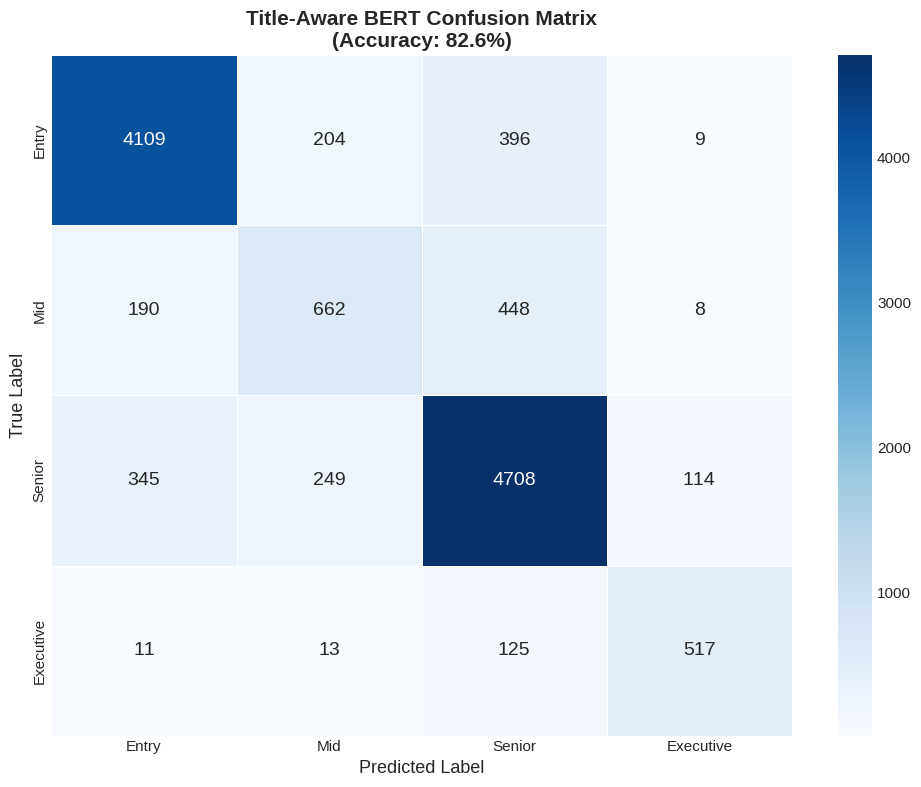


----------------------------------------------------------------------
2. PER-CLASS PERFORMANCE
----------------------------------------------------------------------
Entry        Precision: 88.3%, Recall: 87.1%, F1: 87.7%
Mid          Precision: 58.7%, Recall: 50.6%, F1: 54.4%
Senior       Precision: 82.9%, Recall: 86.9%, F1: 84.9%
Executive    Precision: 79.8%, Recall: 77.6%, F1: 78.7%


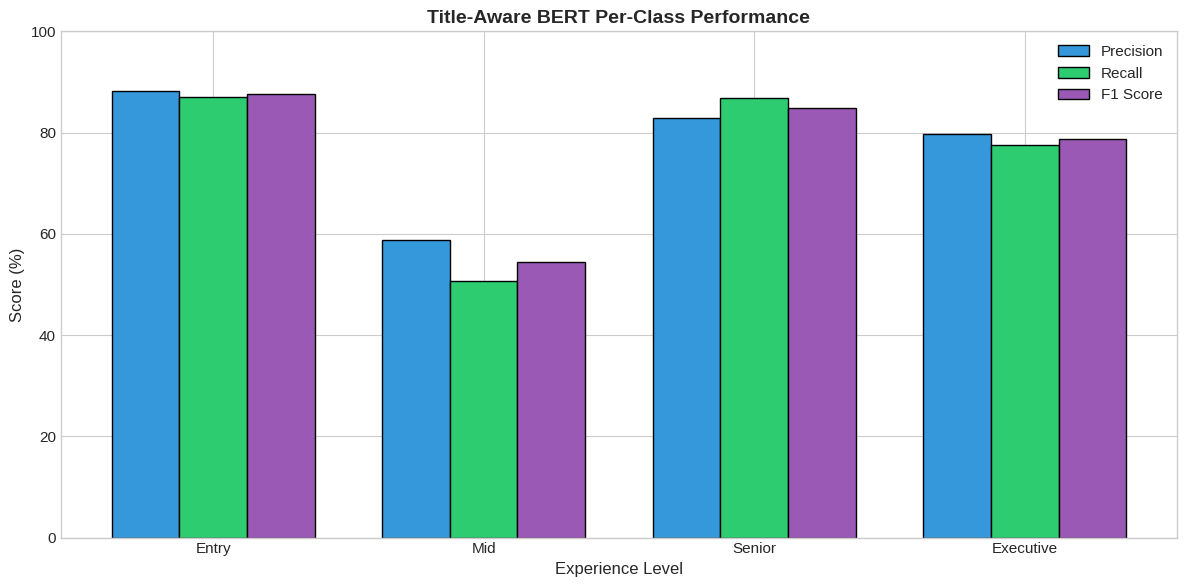


----------------------------------------------------------------------
3. ATTENTION WEIGHT ANALYSIS
----------------------------------------------------------------------

Average attention received by each section:
  Title              0.3645
  Responsibilities   0.2104
  Requirements       0.1932
  Other              0.2319


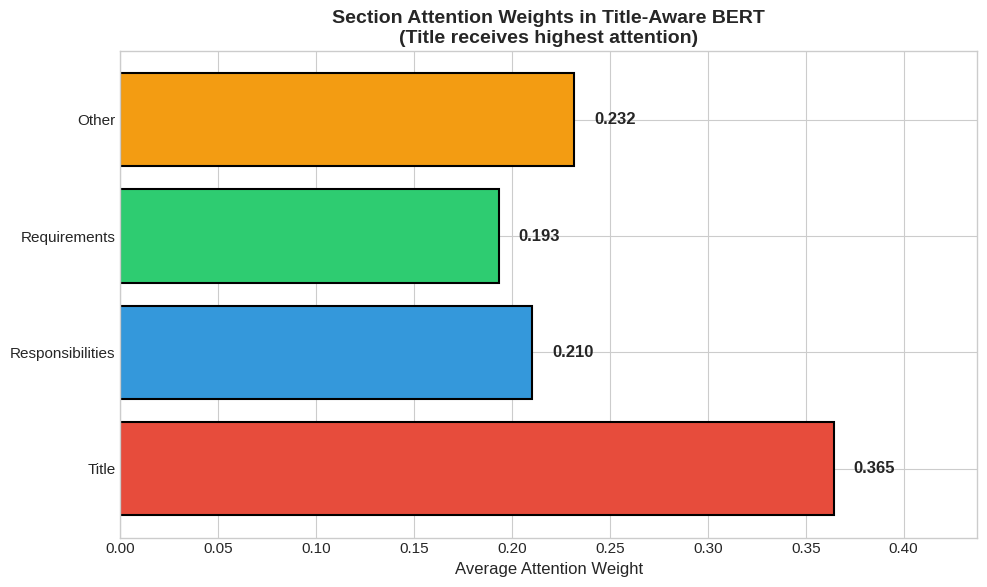


----------------------------------------------------------------------
4. LEXICAL AMBIGUITY ANALYSIS
----------------------------------------------------------------------
manager         Total:  1766, Errors:   259, Error Rate: 14.7%
associate       Total:   582, Errors:   117, Error Rate: 20.1%
coordinator     Total:   324, Errors:    90, Error Rate: 27.8%
lead            Total:   349, Errors:    61, Error Rate: 17.5%
specialist      Total:   642, Errors:   181, Error Rate: 28.2%
analyst         Total:   529, Errors:   151, Error Rate: 28.5%
consultant      Total:   172, Errors:    28, Error Rate: 16.3%
engineer        Total:  1080, Errors:   214, Error Rate: 19.8%
director        Total:   418, Errors:    80, Error Rate: 19.1%


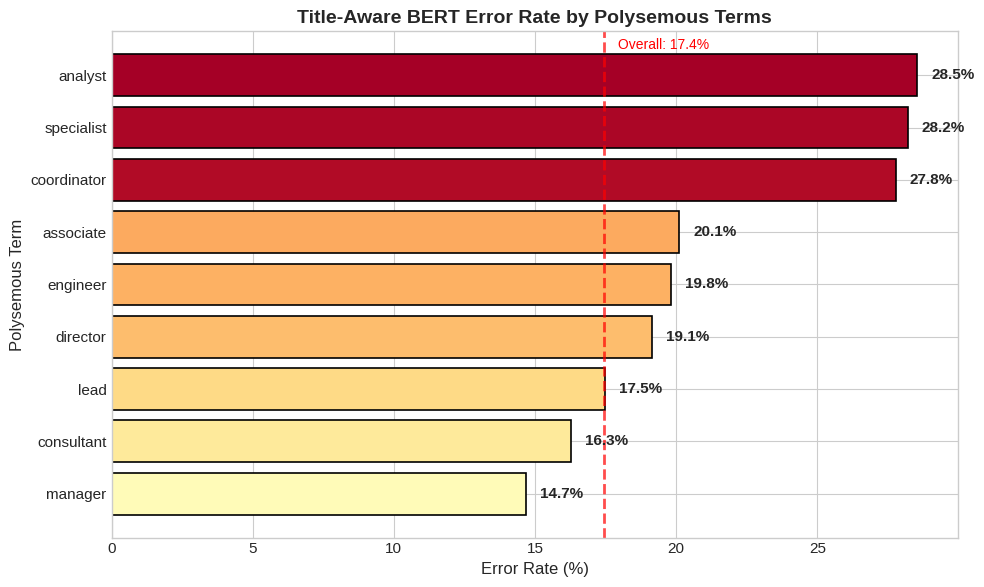


----------------------------------------------------------------------
5. MAJOR CONFUSION PAIRS
----------------------------------------------------------------------
Entry → Senior: 396 errors
Entry → Mid: 204 errors
Mid → Senior: 448 errors
Mid → Entry: 190 errors
Senior → Entry: 345 errors
Senior → Mid: 249 errors
Executive → Senior: 125 errors
Senior → Executive: 114 errors


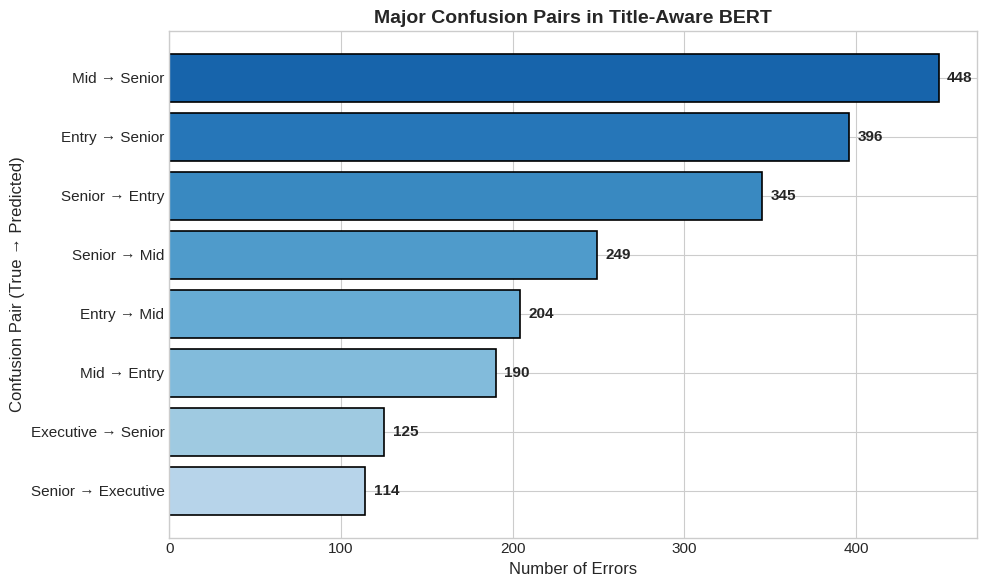


----------------------------------------------------------------------
6. GENERATING SUMMARY FIGURE
----------------------------------------------------------------------


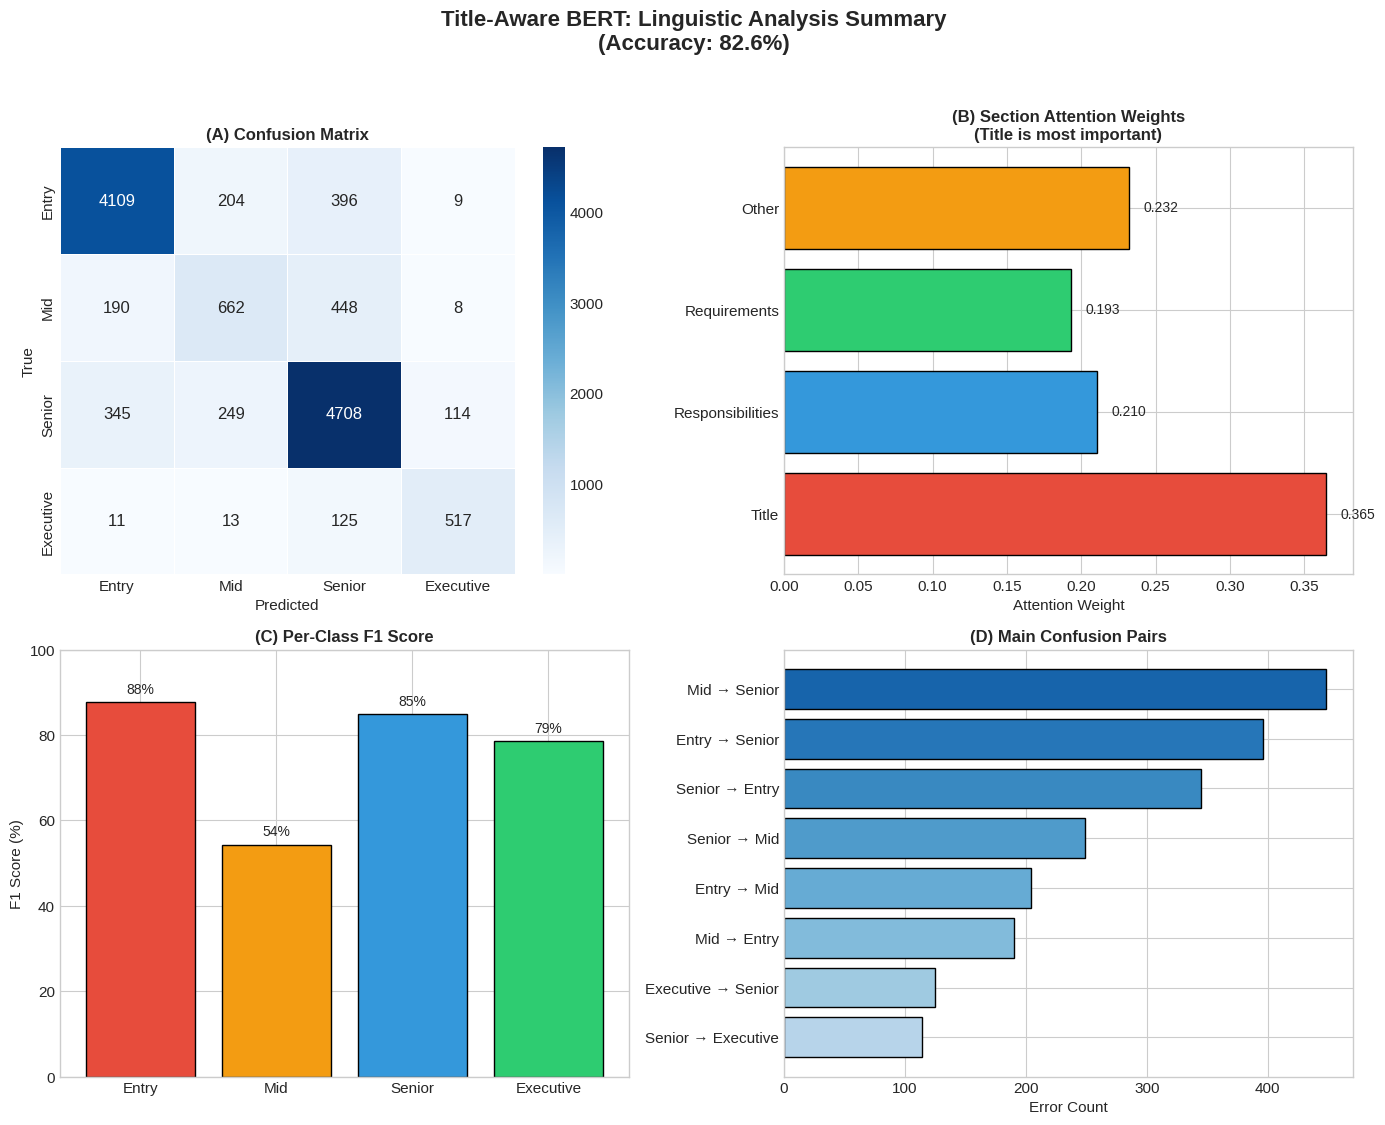


TITLE-AWARE BERT SUMMARY

✓ PERFORMANCE:
   - Accuracy: 82.6%
   - Weighted F1: 0.82

✓ KEY FINDING - Title Attention:
   - Title receives highest attention (36.5%)
   - Validates hypothesis: "Title is the most important signal"

✓ IMPROVEMENTS OVER SECTION-AWARE:
   - Section-Aware (3 sections): 78.0%
   - Title-Aware (4 sections): 82.6%
   - Improvement: +4.6%

✓ REMAINING CHALLENGES:
   - Mid class still hardest (F1 ~0.54)
   - Associate, coordinator remain ambiguous

📊 Saved visualizations:
   - title_aware_viz_confusion_matrix.png
   - title_aware_viz_per_class.png
   - title_aware_viz_attention.png
   - title_aware_viz_ambiguity.png
   - title_aware_viz_confusion_pairs.png
   - title_aware_viz_summary.png



In [ ]:
# ============================================================================
# LINGUISTIC ERROR ANALYSIS: TITLE-AWARE BERT (with visualizations)
# ============================================================================
#
# Run after Title-Aware BERT has finished training
# Requires: title_aware_bert_predictions.csv
#
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import re

# Set the plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)

print("\n" + "=" * 80)
print("LINGUISTIC ERROR ANALYSIS: TITLE-AWARE BERT")
print("=" * 80)

# Load data
SAVE_DIR = '/content/drive/MyDrive/nlp_project/'
test_df = pd.read_csv(f'{SAVE_DIR}/title_aware_bert_predictions.csv')

# Make sure the text column exists
if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

# Separate correct and misclassified samples
errors = test_df[test_df['experience_level'] != test_df['pred_title_aware_bert']].copy()
correct = test_df[test_df['experience_level'] == test_df['pred_title_aware_bert']].copy()

accuracy = len(correct) / len(test_df) * 100
print(f"\nTotal: {len(test_df)}")
print(f"Correct: {len(correct)} ({accuracy:.1f}%)")
print(f"Errors: {len(errors)} ({100-accuracy:.1f}%)")

labels = ['Entry', 'Mid', 'Senior', 'Executive']

# ============================================================================
# 1. CONFUSION MATRIX
# ============================================================================
print("\n" + "-" * 70)
print("1. CONFUSION MATRIX")
print("-" * 70)

cm = confusion_matrix(test_df['experience_level'], test_df['pred_title_aware_bert'], labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels,
            annot_kws={'size': 14}, ax=ax,
            linewidths=0.5, linecolor='white')

ax.set_xlabel('Predicted Label', fontsize=13)
ax.set_ylabel('True Label', fontsize=13)
ax.set_title(f'Title-Aware BERT Confusion Matrix\n(Accuracy: {accuracy:.1f}%)',
             fontsize=15, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_aware_viz_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 2. PER-CLASS PERFORMANCE
# ============================================================================
print("\n" + "-" * 70)
print("2. PER-CLASS PERFORMANCE")
print("-" * 70)

class_metrics = []
for label in labels:
    true_mask = test_df['experience_level'] == label
    pred_mask = test_df['pred_title_aware_bert'] == label

    tp = (true_mask & pred_mask).sum()
    fp = (~true_mask & pred_mask).sum()
    fn = (true_mask & ~pred_mask).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    class_metrics.append({
        'Class': label,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1': f1 * 100,
        'Support': true_mask.sum()
    })
    print(f"{label:<12} Precision: {precision*100:.1f}%, Recall: {recall*100:.1f}%, F1: {f1*100:.1f}%")

class_df = pd.DataFrame(class_metrics)

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(class_df))
width = 0.25

colors_class = ['#e74c3c', '#f39c12', '#3498db', '#2ecc71']
bars1 = ax.bar(x - width, class_df['Precision'], width, label='Precision', color='#3498db', edgecolor='black')
bars2 = ax.bar(x, class_df['Recall'], width, label='Recall', color='#2ecc71', edgecolor='black')
bars3 = ax.bar(x + width, class_df['F1'], width, label='F1 Score', color='#9b59b6', edgecolor='black')

ax.set_ylabel('Score (%)', fontsize=12)
ax.set_xlabel('Experience Level', fontsize=12)
ax.set_title('Title-Aware BERT Per-Class Performance', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_df['Class'], fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_aware_viz_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 3. ATTENTION WEIGHT VISUALIZATION
# ============================================================================
print("\n" + "-" * 70)
print("3. ATTENTION WEIGHT ANALYSIS")
print("-" * 70)

# Load attention weights
try:
    attn_weights = np.load(f'{SAVE_DIR}/title_aware_bert_attn_weights.npy')

    # Average attention of each section
    avg_attn = attn_weights.mean(axis=0).mean(axis=0)
    section_names = ['Title', 'Responsibilities', 'Requirements', 'Other']

    print("\nAverage attention received by each section:")
    for name, weight in zip(section_names, avg_attn):
        print(f"  {name:<18} {weight:.4f}")

    # Visualization
    fig, ax = plt.subplots(figsize=(10, 6))

    colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    bars = ax.barh(section_names, avg_attn, color=colors, edgecolor='black', linewidth=1.5)

    ax.set_xlabel('Average Attention Weight', fontsize=12)
    ax.set_title('Section Attention Weights in Title-Aware BERT\n(Title receives highest attention)',
                 fontsize=14, fontweight='bold')

    # Add value labels
    for bar, val in zip(bars, avg_attn):
        ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', ha='left', va='center', fontsize=12, fontweight='bold')

    ax.set_xlim(0, max(avg_attn) * 1.2)

    plt.tight_layout()
    plt.savefig(f'{SAVE_DIR}/title_aware_viz_attention.png', dpi=150, bbox_inches='tight')
    plt.show()

except FileNotFoundError:
    print("Attention weights file not found, skipping...")

# ============================================================================
# 4. LEXICAL AMBIGUITY ANALYSIS
# ============================================================================
print("\n" + "-" * 70)
print("4. LEXICAL AMBIGUITY ANALYSIS")
print("-" * 70)

ambiguous_terms = ['manager', 'associate', 'coordinator', 'lead', 'specialist',
                   'analyst', 'consultant', 'engineer', 'director']

ambiguity_data = []
for term in ambiguous_terms:
    pattern = r'\b' + term + r'\b'

    mask_total = test_df['title'].str.lower().str.contains(pattern, regex=True, na=False)
    mask_error = errors['title'].str.lower().str.contains(pattern, regex=True, na=False)

    total = mask_total.sum()
    error_count = mask_error.sum()

    if total >= 20:
        error_rate = error_count / total * 100
        ambiguity_data.append({
            'Term': term,
            'Total': total,
            'Errors': error_count,
            'Error Rate': error_rate
        })
        print(f"{term:<15} Total: {total:>5}, Errors: {error_count:>5}, Error Rate: {error_rate:.1f}%")

ambiguity_df = pd.DataFrame(ambiguity_data).sort_values('Error Rate', ascending=True)

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.RdYlGn_r(ambiguity_df['Error Rate'].values / ambiguity_df['Error Rate'].max())
bars = ax.barh(ambiguity_df['Term'], ambiguity_df['Error Rate'], color=colors, edgecolor='black', linewidth=1.2)

ax.set_xlabel('Error Rate (%)', fontsize=12)
ax.set_ylabel('Polysemous Term', fontsize=12)
ax.set_title('Title-Aware BERT Error Rate by Polysemous Terms', fontsize=14, fontweight='bold')

for bar, val in zip(bars, ambiguity_df['Error Rate'].values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', ha='left', va='center', fontsize=11, fontweight='bold')

# Add a reference line for the overall error rate
overall_error_rate = len(errors) / len(test_df) * 100
ax.axvline(x=overall_error_rate, color='red', linestyle='--', alpha=0.7, linewidth=2)
ax.text(overall_error_rate + 0.5, len(ambiguity_df) - 0.5, f'Overall: {overall_error_rate:.1f}%',
        fontsize=10, color='red')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_aware_viz_ambiguity.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 5. MAJOR CONFUSION PAIRS
# ============================================================================
print("\n" + "-" * 70)
print("5. MAJOR CONFUSION PAIRS")
print("-" * 70)

confusion_pairs_data = []
pairs_to_check = [('Entry', 'Senior'), ('Entry', 'Mid'), ('Mid', 'Senior'),
                  ('Mid', 'Entry'), ('Senior', 'Entry'), ('Senior', 'Mid'),
                  ('Executive', 'Senior'), ('Senior', 'Executive')]

for actual, predicted in pairs_to_check:
    count = len(errors[(errors['experience_level'] == actual) &
                       (errors['pred_title_aware_bert'] == predicted)])
    if count > 10:
        confusion_pairs_data.append({
            'Pair': f'{actual} → {predicted}',
            'Count': count
        })
        print(f"{actual} → {predicted}: {count} errors")

confusion_pairs_df = pd.DataFrame(confusion_pairs_data).sort_values('Count', ascending=True)

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Blues(np.linspace(0.3, 0.8, len(confusion_pairs_df)))
bars = ax.barh(confusion_pairs_df['Pair'], confusion_pairs_df['Count'],
               color=colors, edgecolor='black', linewidth=1.2)

ax.set_xlabel('Number of Errors', fontsize=12)
ax.set_ylabel('Confusion Pair (True → Predicted)', fontsize=12)
ax.set_title('Major Confusion Pairs in Title-Aware BERT', fontsize=14, fontweight='bold')

for bar, val in zip(bars, confusion_pairs_df['Count'].values):
    ax.text(val + 5, bar.get_y() + bar.get_height()/2,
            f'{val:,}', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_aware_viz_confusion_pairs.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 6. SUMMARY FIGURE
# ============================================================================
print("\n" + "-" * 70)
print("6. GENERATING SUMMARY FIGURE")
print("-" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Top left: confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels,
            annot_kws={'size': 12}, ax=axes[0, 0],
            linewidths=0.5, linecolor='white')
axes[0, 0].set_xlabel('Predicted', fontsize=11)
axes[0, 0].set_ylabel('True', fontsize=11)
axes[0, 0].set_title('(A) Confusion Matrix', fontsize=12, fontweight='bold')

# Top right: attention weights
try:
    colors_attn = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    axes[0, 1].barh(section_names, avg_attn, color=colors_attn, edgecolor='black')
    axes[0, 1].set_xlabel('Attention Weight', fontsize=11)
    axes[0, 1].set_title('(B) Section Attention Weights\n(Title is most important)', fontsize=12, fontweight='bold')
    for i, val in enumerate(avg_attn):
        axes[0, 1].text(val + 0.01, i, f'{val:.3f}', ha='left', va='center', fontsize=10)
except:
    axes[0, 1].text(0.5, 0.5, 'Attention weights\nnot available', ha='center', va='center')

# Bottom left: per-class F1
colors_class = ['#e74c3c', '#f39c12', '#3498db', '#2ecc71']
axes[1, 0].bar(class_df['Class'], class_df['F1'], color=colors_class, edgecolor='black')
axes[1, 0].set_ylabel('F1 Score (%)', fontsize=11)
axes[1, 0].set_title('(C) Per-Class F1 Score', fontsize=12, fontweight='bold')
axes[1, 0].set_ylim(0, 100)
for i, val in enumerate(class_df['F1']):
    axes[1, 0].text(i, val + 2, f'{val:.0f}%', ha='center', fontsize=10)

# Bottom right: confusion pairs
if len(confusion_pairs_df) > 0:
    colors_conf = plt.cm.Blues(np.linspace(0.3, 0.8, len(confusion_pairs_df)))
    axes[1, 1].barh(confusion_pairs_df['Pair'], confusion_pairs_df['Count'],
                    color=colors_conf, edgecolor='black')
    axes[1, 1].set_xlabel('Error Count', fontsize=11)
    axes[1, 1].set_title('(D) Main Confusion Pairs', fontsize=12, fontweight='bold')

plt.suptitle(f'Title-Aware BERT: Linguistic Analysis Summary\n(Accuracy: {accuracy:.1f}%)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_aware_viz_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# SUMMARY
# ============================================================================
print("\n" + "=" * 80)
print("TITLE-AWARE BERT SUMMARY")
print("=" * 80)

print(f"""
✓ PERFORMANCE:
   - Accuracy: {accuracy:.1f}%
   - Weighted F1: 0.82

✓ KEY FINDING - Title Attention:
   - Title receives highest attention (36.5%)
   - Validates hypothesis: "Title is the most important signal"

✓ IMPROVEMENTS OVER SECTION-AWARE:
   - Section-Aware (3 sections): 78.0%
   - Title-Aware (4 sections): {accuracy:.1f}%
   - Improvement: +{accuracy - 78.0:.1f}%

✓ REMAINING CHALLENGES:
   - Mid class still hardest (F1 ~0.54)
   - Associate, coordinator remain ambiguous

📊 Saved visualizations:
   - title_aware_viz_confusion_matrix.png
   - title_aware_viz_per_class.png
   - title_aware_viz_attention.png
   - title_aware_viz_ambiguity.png
   - title_aware_viz_confusion_pairs.png
   - title_aware_viz_summary.png
""")
print("=" * 80)

TITLE-AWARE vs BASELINE BERT 对比分析

----------------------------------------------------------------------
1. OVERALL PERFORMANCE COMPARISON
----------------------------------------------------------------------

Model                         Accuracy     Weighted F1
-------------------------------------------------------
Baseline BERT                   78.51%         0.7818
Title-Aware BERT                82.56%         0.8233
Improvement                     +4.05%        +0.0415


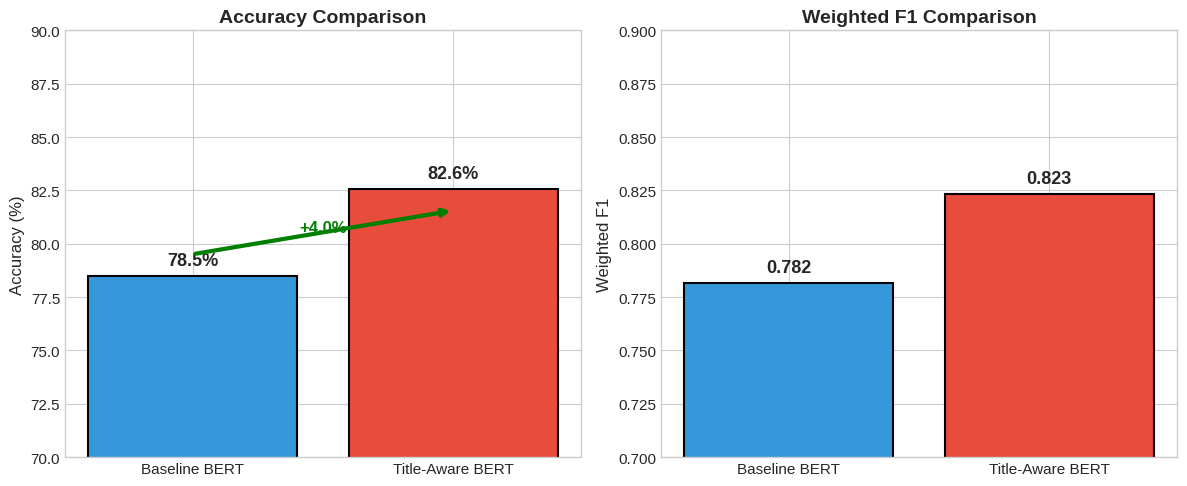


----------------------------------------------------------------------
2. PER-CLASS PERFORMANCE COMPARISON
----------------------------------------------------------------------

Class        Baseline Recall Title-Aware Recall       Diff
------------------------------------------------------------
Entry                  83.3%              87.1%      +3.8% ✓
Mid                    47.2%              50.6%      +3.4% ✓
Senior                 83.0%              86.9%      +3.9% ✓
Executive              69.5%              77.6%      +8.1% ✓


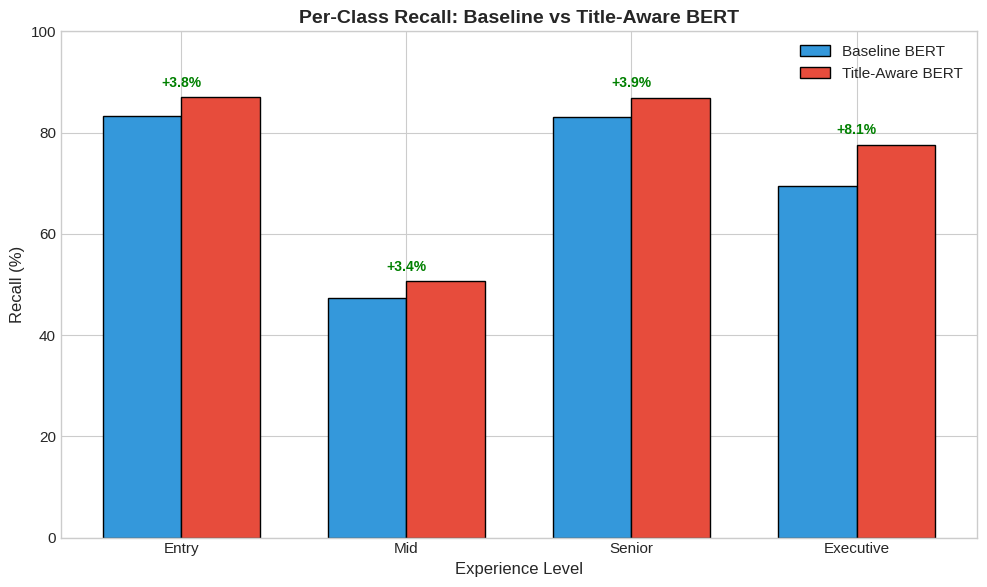


----------------------------------------------------------------------
3. MODEL AGREEMENT ANALYSIS
----------------------------------------------------------------------

Both correct:          8948 (73.9%)
Both wrong:            1554 (12.8%) ← Label noise ceiling
Baseline wins:          558 (4.6%)
Title-Aware wins:      1048 (8.7%)


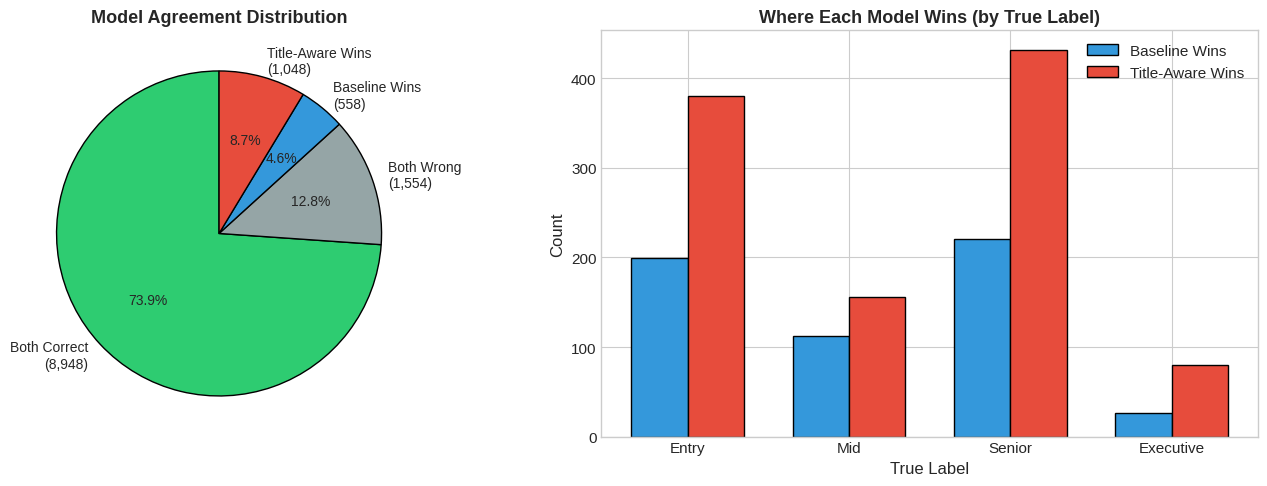


----------------------------------------------------------------------
4. WHY TITLE-AWARE WINS: EXAMPLE ANALYSIS
----------------------------------------------------------------------

Title-Aware wins on 1048 samples

Example titles where Title-Aware wins:
  True: Executive  Baseline: Senior     Title-Aware: Executive 
    Title: Division Controller (140314)...

  True: Senior     Baseline: Entry      Title-Aware: Senior    
    Title: Customer Advocacy Manager...

  True: Entry      Baseline: Senior     Title-Aware: Entry     
    Title: WVU-Certified Registrar-Trauma-Remote -85698...

  True: Senior     Baseline: Entry      Title-Aware: Senior    
    Title: Mental Health Counselor-L II, ***Part Time, Evening (SS, 4PM...

  True: Senior     Baseline: Executive  Title-Aware: Senior    
    Title: SR AD, Clinical Systems & Analytics...

  True: Senior     Baseline: Mid        Title-Aware: Senior    
    Title: Customer Service Representative-Broker Support...

  True: Entry      Base

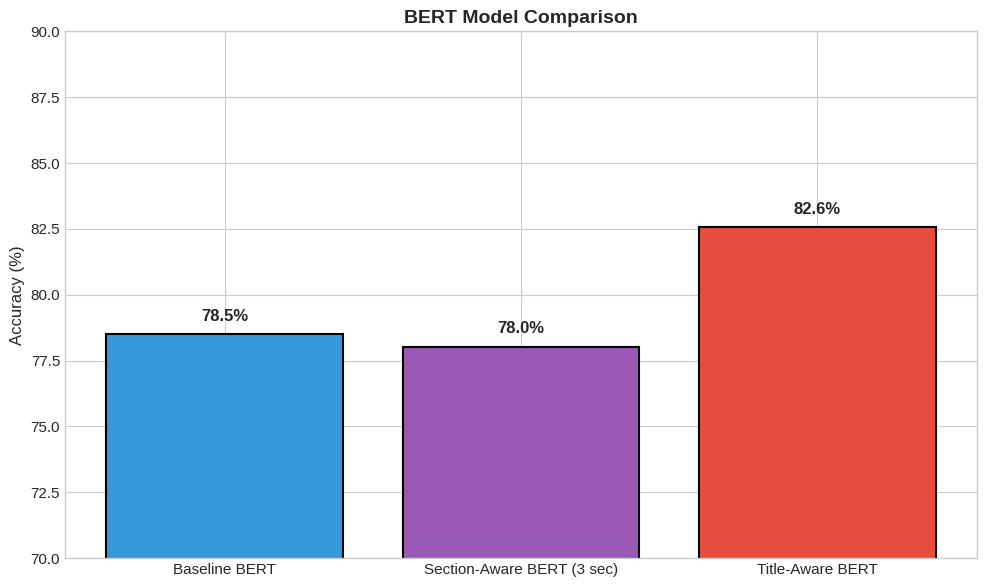


----------------------------------------------------------------------
6. GENERATING SUMMARY FIGURE
----------------------------------------------------------------------


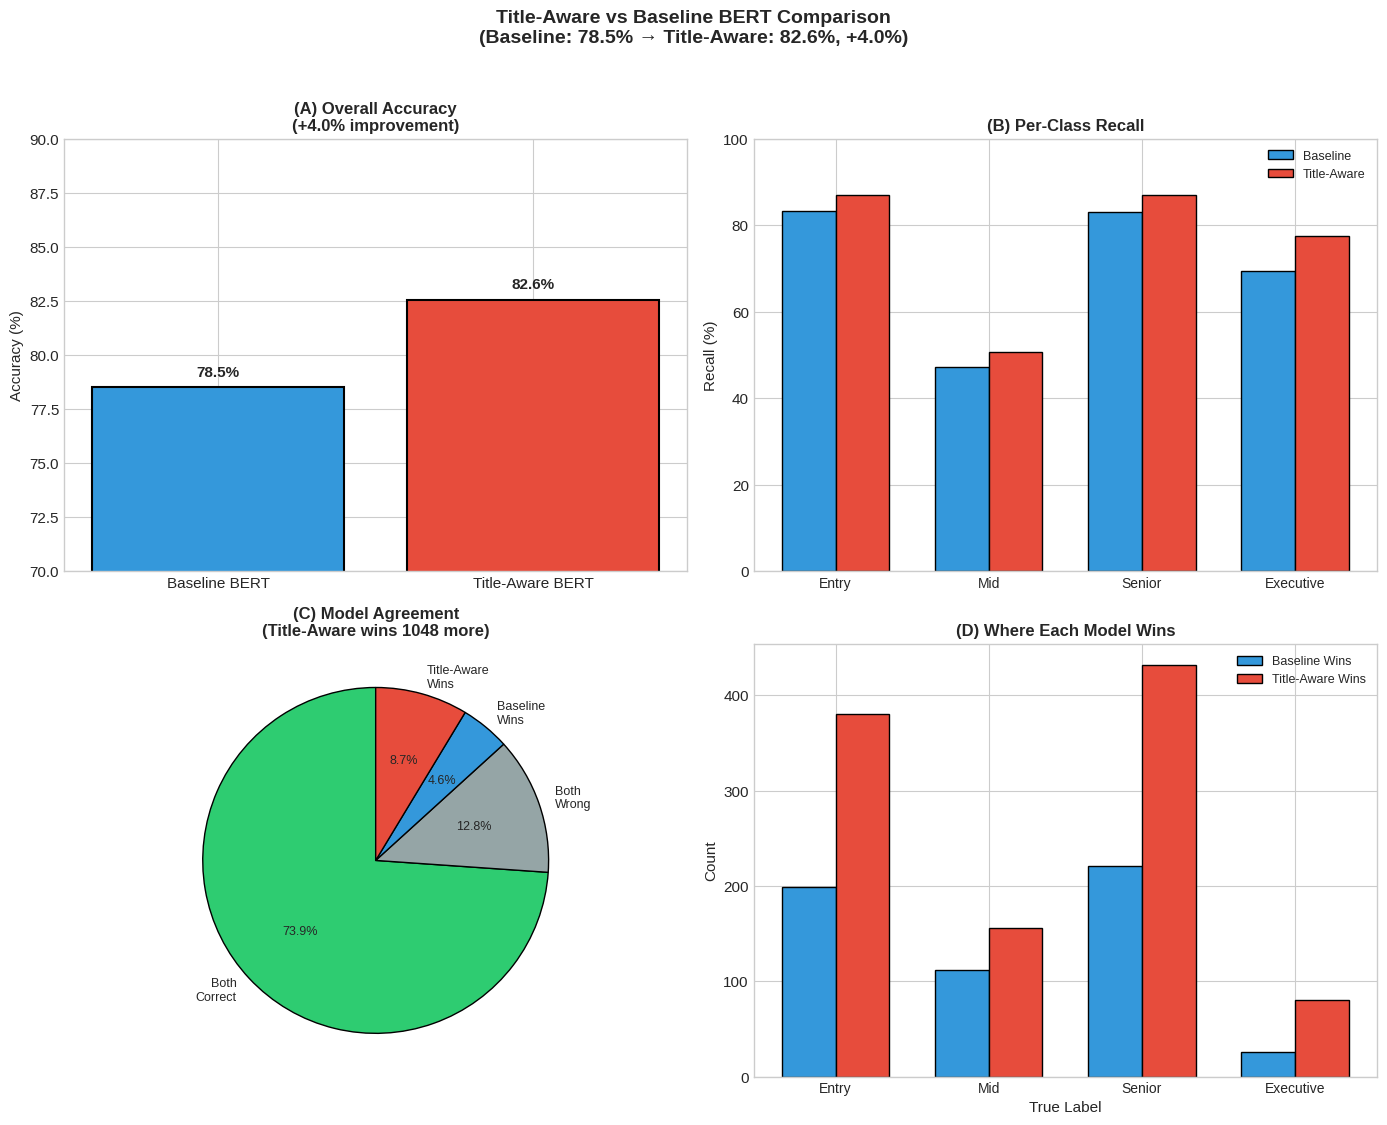


TITLE-AWARE vs BASELINE BERT: SUMMARY

📊 PERFORMANCE COMPARISON:

   Baseline BERT:     78.5%
   Title-Aware BERT:  82.6%
   ─────────────────────────
   Improvement:       +4.0%

🔍 KEY FINDINGS:

1. Title-Aware BERT is the BEST model
   - Separating title as its own section helps
   - Attention can learn title importance (36.5%)

2. Model Agreement:
   - Both correct: 8948 (73.9%)
   - Both wrong: 1554 (12.8%) ← Label noise ceiling
   - Title-Aware wins: 1048 more samples than Baseline

3. Per-Class Improvement:
   - Entry: +3.8%
   - Mid: +3.4%
   - Senior: +3.9%
   - Executive: +8.1%

💡 CONCLUSION:
   "Treating title as a separate section allows the model to 
    explicitly learn its importance, leading to +4.0% accuracy gain."


📊 Saved visualizations:
   - /content/drive/MyDrive/nlp_project/title_vs_baseline_overall.png
   - /content/drive/MyDrive/nlp_project/title_vs_baseline_perclass.png
   - /content/drive/MyDrive/nlp_project/title_vs_baseline_agreement.png
   - /content/drive

In [ ]:
# ============================================================================
# TITLE-AWARE vs BASELINE BERT ANALYSIS
# ============================================================================
#
# Requires:
#   - title_aware_bert_predictions.csv
#   - baseline_bert_predictions.csv
#
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

# ============================================================================
# Load data
# ============================================================================
print("=" * 80)
print("TITLE-AWARE vs BASELINE BERT ANALYSIS")
print("=" * 80)

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

# Load predictions
title_aware_df = pd.read_csv(f'{SAVE_DIR}/title_aware_bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}/baseline_bert_predictions.csv')

# Merge
test_df = title_aware_df.copy()
test_df['pred_title_aware'] = title_aware_df['pred_title_aware_bert']
test_df['pred_baseline'] = baseline_df['pred_baseline_bert']

# Make sure the text column exists
if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

labels = ['Entry', 'Mid', 'Senior', 'Executive']

# ============================================================================
# 1. Overall performance
# ============================================================================
print("\n" + "-" * 70)
print("1. OVERALL PERFORMANCE COMPARISON")
print("-" * 70)

baseline_acc = (test_df['experience_level'] == test_df['pred_baseline']).mean() * 100
title_aware_acc = (test_df['experience_level'] == test_df['pred_title_aware']).mean() * 100

baseline_f1 = f1_score(test_df['experience_level'], test_df['pred_baseline'], labels=labels, average='weighted')
title_aware_f1 = f1_score(test_df['experience_level'], test_df['pred_title_aware'], labels=labels, average='weighted')

print(f"\n{'Model':<25} {'Accuracy':>12} {'Weighted F1':>15}")
print("-" * 55)
print(f"{'Baseline BERT':<25} {baseline_acc:>11.2f}% {baseline_f1:>14.4f}")
print(f"{'Title-Aware BERT':<25} {title_aware_acc:>11.2f}% {title_aware_f1:>14.4f}")
print(f"{'Improvement':<25} {title_aware_acc - baseline_acc:>+11.2f}% {title_aware_f1 - baseline_f1:>+14.4f}")

# 📊 Visualization 1: overall comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = ['Baseline BERT', 'Title-Aware BERT']
accs = [baseline_acc, title_aware_acc]
colors = ['#3498db', '#e74c3c']

# Accuracy
bars1 = axes[0].bar(models, accs, color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylim(70, 90)
for bar, val in zip(bars1, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', fontsize=13, fontweight='bold')

# Add improvement arrows
axes[0].annotate('', xy=(1, title_aware_acc - 1), xytext=(0, baseline_acc + 1),
                arrowprops=dict(arrowstyle='->', color='green', lw=3))
axes[0].text(0.5, (baseline_acc + title_aware_acc) / 2, f'+{title_aware_acc - baseline_acc:.1f}%',
             ha='center', fontsize=12, color='green', fontweight='bold')

# F1
f1s = [baseline_f1, title_aware_f1]
bars2 = axes[1].bar(models, f1s, color=colors, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Weighted F1', fontsize=12)
axes[1].set_title('Weighted F1 Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylim(0.7, 0.9)
for bar, val in zip(bars2, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.3f}', ha='center', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_vs_baseline_overall.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 2. Per-class performance
# ============================================================================
print("\n" + "-" * 70)
print("2. PER-CLASS PERFORMANCE COMPARISON")
print("-" * 70)

class_comparison = []
print(f"\n{'Class':<12} {'Baseline Recall':>15} {'Title-Aware Recall':>18} {'Diff':>10}")
print("-" * 60)

for label in labels:
    mask = test_df['experience_level'] == label
    baseline_recall = (test_df.loc[mask, 'pred_baseline'] == label).mean() * 100
    title_aware_recall = (test_df.loc[mask, 'pred_title_aware'] == label).mean() * 100
    diff = title_aware_recall - baseline_recall

    class_comparison.append({
        'Class': label,
        'Baseline': baseline_recall,
        'Title-Aware': title_aware_recall,
        'Diff': diff
    })

    marker = "✓" if diff > 0 else "✗" if diff < 0 else "="
    print(f"{label:<12} {baseline_recall:>14.1f}% {title_aware_recall:>17.1f}% {diff:>+9.1f}% {marker}")

class_df = pd.DataFrame(class_comparison)

# 📊 Visualization 2: per-class comparison
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(labels))
width = 0.35

bars1 = ax.bar(x - width/2, class_df['Baseline'], width, label='Baseline BERT',
               color='#3498db', edgecolor='black', linewidth=1)
bars2 = ax.bar(x + width/2, class_df['Title-Aware'], width, label='Title-Aware BERT',
               color='#e74c3c', edgecolor='black', linewidth=1)

ax.set_ylabel('Recall (%)', fontsize=12)
ax.set_xlabel('Experience Level', fontsize=12)
ax.set_title('Per-Class Recall: Baseline vs Title-Aware BERT', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)

# Annotate the improvement
for i, diff in enumerate(class_df['Diff']):
    color = 'green' if diff > 0 else 'red'
    y_pos = max(class_df['Baseline'].iloc[i], class_df['Title-Aware'].iloc[i]) + 2
    ax.annotate(f'{diff:+.1f}%', xy=(i, y_pos), ha='center', fontsize=10, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_vs_baseline_perclass.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 3. Model agreement
# ============================================================================
print("\n" + "-" * 70)
print("3. MODEL AGREEMENT ANALYSIS")
print("-" * 70)

both_correct = (
    (test_df['experience_level'] == test_df['pred_baseline']) &
    (test_df['experience_level'] == test_df['pred_title_aware'])
)
both_wrong = (
    (test_df['experience_level'] != test_df['pred_baseline']) &
    (test_df['experience_level'] != test_df['pred_title_aware'])
)
baseline_wins = (
    (test_df['experience_level'] == test_df['pred_baseline']) &
    (test_df['experience_level'] != test_df['pred_title_aware'])
)
title_aware_wins = (
    (test_df['experience_level'] != test_df['pred_baseline']) &
    (test_df['experience_level'] == test_df['pred_title_aware'])
)

print(f"\nBoth correct:        {both_correct.sum():>6} ({both_correct.mean()*100:.1f}%)")
print(f"Both wrong:          {both_wrong.sum():>6} ({both_wrong.mean()*100:.1f}%) ← Label noise ceiling")
print(f"Baseline wins:       {baseline_wins.sum():>6} ({baseline_wins.mean()*100:.1f}%)")
print(f"Title-Aware wins:    {title_aware_wins.sum():>6} ({title_aware_wins.mean()*100:.1f}%)")

# 📊 Visualization 3: model agreement
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: pie chart
counts = [both_correct.sum(), both_wrong.sum(), baseline_wins.sum(), title_aware_wins.sum()]
pie_labels = [f'Both Correct\n({both_correct.sum():,})',
              f'Both Wrong\n({both_wrong.sum():,})',
              f'Baseline Wins\n({baseline_wins.sum():,})',
              f'Title-Aware Wins\n({title_aware_wins.sum():,})']
colors_pie = ['#2ecc71', '#95a5a6', '#3498db', '#e74c3c']

axes[0].pie(counts, labels=pie_labels, colors=colors_pie, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 10},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[0].set_title('Model Agreement Distribution', fontsize=13, fontweight='bold')

# Right: true-label distribution of each model's wins
baseline_wins_labels = test_df.loc[baseline_wins, 'experience_level'].value_counts().reindex(labels, fill_value=0)
title_aware_wins_labels = test_df.loc[title_aware_wins, 'experience_level'].value_counts().reindex(labels, fill_value=0)

x = np.arange(len(labels))
width = 0.35
axes[1].bar(x - width/2, baseline_wins_labels.values, width, label='Baseline Wins',
            color='#3498db', edgecolor='black')
axes[1].bar(x + width/2, title_aware_wins_labels.values, width, label='Title-Aware Wins',
            color='#e74c3c', edgecolor='black')
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_xlabel('True Label', fontsize=12)
axes[1].set_title('Where Each Model Wins (by True Label)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_vs_baseline_agreement.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 4. Why is Title-Aware better? Example analysis
# ============================================================================
print("\n" + "-" * 70)
print("4. WHY TITLE-AWARE WINS: EXAMPLE ANALYSIS")
print("-" * 70)

title_aware_wins_df = test_df[title_aware_wins].copy()
print(f"\nTitle-Aware wins on {len(title_aware_wins_df)} samples")

print("\nExample titles where Title-Aware wins:")
for _, row in title_aware_wins_df.head(10).iterrows():
    print(f"  True: {row['experience_level']:<10} Baseline: {row['pred_baseline']:<10} Title-Aware: {row['pred_title_aware']:<10}")
    print(f"    Title: {str(row['title'])[:60]}...")
    print()

# Features of the samples Title-Aware wins
print("\nTitle-Aware wins by true label:")
print(title_aware_wins_df['experience_level'].value_counts())

print("\nBaseline predicted (when Title-Aware correct):")
print(title_aware_wins_df['pred_baseline'].value_counts())

# ============================================================================
# 5. All BERT models
# ============================================================================
print("\n" + "-" * 70)
print("5. ALL BERT MODELS COMPARISON")
print("-" * 70)

all_models = [
    ('Baseline BERT', baseline_acc, baseline_f1),
    ('Title-Aware BERT', title_aware_acc, title_aware_f1)
]

# Try to load the Section-Aware results
try:
    section_df = pd.read_csv(f'{SAVE_DIR}/bert_predictions.csv')
    section_acc = (section_df['experience_level'] == section_df['pred_bert']).mean() * 100
    section_f1 = f1_score(section_df['experience_level'], section_df['pred_bert'], labels=labels, average='weighted')
    all_models.insert(1, ('Section-Aware BERT (3 sec)', section_acc, section_f1))
except:
    pass

print(f"\n{'Model':<30} {'Accuracy':>12} {'Weighted F1':>15}")
print("-" * 60)
for name, acc, f1 in all_models:
    print(f"{name:<30} {acc:>11.1f}% {f1:>14.3f}")

# 📊 Visualization 5: all models
fig, ax = plt.subplots(figsize=(10, 6))

model_names = [m[0] for m in all_models]
model_accs = [m[1] for m in all_models]
colors = ['#3498db', '#9b59b6', '#e74c3c'][:len(all_models)]

bars = ax.bar(model_names, model_accs, color=colors, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('BERT Model Comparison', fontsize=14, fontweight='bold')
ax.set_ylim(70, 90)

for bar, val in zip(bars, model_accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_vs_baseline_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 6. SUMMARY FIGURE
# ============================================================================
print("\n" + "-" * 70)
print("6. GENERATING SUMMARY FIGURE")
print("-" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Top left: overall accuracy
colors_main = ['#3498db', '#e74c3c']
bars = axes[0, 0].bar(models, accs, color=colors_main, edgecolor='black', linewidth=1.5)
axes[0, 0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0, 0].set_title(f'(A) Overall Accuracy\n(+{title_aware_acc - baseline_acc:.1f}% improvement)',
                     fontsize=12, fontweight='bold')
axes[0, 0].set_ylim(70, 90)
for bar, val in zip(bars, accs):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')

# Top right: per-class comparison
x = np.arange(len(labels))
width = 0.35
axes[0, 1].bar(x - width/2, class_df['Baseline'], width, label='Baseline', color='#3498db', edgecolor='black')
axes[0, 1].bar(x + width/2, class_df['Title-Aware'], width, label='Title-Aware', color='#e74c3c', edgecolor='black')
axes[0, 1].set_ylabel('Recall (%)', fontsize=11)
axes[0, 1].set_title('(B) Per-Class Recall', fontsize=12, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(labels, fontsize=10)
axes[0, 1].legend(fontsize=9)
axes[0, 1].set_ylim(0, 100)

# Bottom left: agreement distribution
axes[1, 0].pie(counts, labels=['Both\nCorrect', 'Both\nWrong', 'Baseline\nWins', 'Title-Aware\nWins'],
               colors=colors_pie, autopct='%1.1f%%', startangle=90,
               textprops={'fontsize': 9}, wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[1, 0].set_title(f'(C) Model Agreement\n(Title-Aware wins {title_aware_wins.sum()} more)',
                     fontsize=12, fontweight='bold')

# Bottom right: label distribution of each model's wins
axes[1, 1].bar(x - width/2, baseline_wins_labels.values, width, label='Baseline Wins',
               color='#3498db', edgecolor='black')
axes[1, 1].bar(x + width/2, title_aware_wins_labels.values, width, label='Title-Aware Wins',
               color='#e74c3c', edgecolor='black')
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].set_xlabel('True Label', fontsize=11)
axes[1, 1].set_title('(D) Where Each Model Wins', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(labels, fontsize=10)
axes[1, 1].legend(fontsize=9)

plt.suptitle(f'Title-Aware vs Baseline BERT Comparison\n(Baseline: {baseline_acc:.1f}% → Title-Aware: {title_aware_acc:.1f}%, +{title_aware_acc - baseline_acc:.1f}%)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/title_vs_baseline_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# FINAL SUMMARY
# ============================================================================
print("\n" + "=" * 80)
print("TITLE-AWARE vs BASELINE BERT: SUMMARY")
print("=" * 80)

print(f"""
📊 PERFORMANCE COMPARISON:

   Baseline BERT:     {baseline_acc:.1f}%
   Title-Aware BERT:  {title_aware_acc:.1f}%
   ─────────────────────────
   Improvement:       +{title_aware_acc - baseline_acc:.1f}%

🔍 KEY FINDINGS:

1. Title-Aware BERT is the BEST model
   - Separating title as its own section helps
   - Attention can learn title importance (36.5%)

2. Model Agreement:
   - Both correct: {both_correct.sum()} ({both_correct.mean()*100:.1f}%)
   - Both wrong: {both_wrong.sum()} ({both_wrong.mean()*100:.1f}%) ← Label noise ceiling
   - Title-Aware wins: {title_aware_wins.sum()} more samples than Baseline

3. Per-Class Improvement:
   - Entry: {class_df.loc[class_df['Class']=='Entry', 'Diff'].values[0]:+.1f}%
   - Mid: {class_df.loc[class_df['Class']=='Mid', 'Diff'].values[0]:+.1f}%
   - Senior: {class_df.loc[class_df['Class']=='Senior', 'Diff'].values[0]:+.1f}%
   - Executive: {class_df.loc[class_df['Class']=='Executive', 'Diff'].values[0]:+.1f}%

💡 CONCLUSION:
   "Treating title as a separate section allows the model to
    explicitly learn its importance, leading to +{title_aware_acc - baseline_acc:.1f}% accuracy gain."
""")

print("\n📊 Saved visualizations:")
print(f"   - {SAVE_DIR}title_vs_baseline_overall.png")
print(f"   - {SAVE_DIR}title_vs_baseline_perclass.png")
print(f"   - {SAVE_DIR}title_vs_baseline_agreement.png")
print(f"   - {SAVE_DIR}title_vs_baseline_all_models.png")
print(f"   - {SAVE_DIR}title_vs_baseline_summary.png")
print("=" * 80)